In [1]:
print("応用、始めます")

応用、始めます


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

raw = load_breast_cancer(as_frame=True)
X = raw.data
y = (raw.target == 0).astype(int)
names = list(X.columns)
Xdev, Xte, ydev, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
print("開発用:", len(ydev), "／ テスト用:", len(yte))

開発用: 455 ／ テスト用: 114


In [3]:
pipe = make_pipeline(StandardScaler(), SelectKBest(f_classif), LogisticRegression(max_iter=500))
grid = {"selectkbest__k": [2, 5, 10, 30],
        "logisticregression__C": [0.1, 1, 10]}
rows = []
for seed in range(10):
    Xa, Xr, ya, yr = train_test_split(X, y, train_size=40, stratify=y, random_state=seed)
    inner = StratifiedKFold(5, shuffle=True, random_state=seed)
    g = GridSearchCV(pipe, grid, cv=inner, scoring="roc_auc").fit(Xa, ya)
    truth = roc_auc_score(yr, g.decision_function(Xr))
    outer = StratifiedKFold(5, shuffle=True, random_state=100 + seed)
    nested = cross_val_score(GridSearchCV(pipe, grid, cv=inner, scoring="roc_auc"), Xa, ya, cv=outer, scoring="roc_auc").mean()
    rows.append((g.best_score_, nested, truth))
r = pd.DataFrame(rows, columns=["plain", "nested", "truth"])
print(r.round(3).to_string())
print("\n平均:", r.mean().round(4).to_dict())
print("plain − truth の平均:", round((r.plain - r.truth).mean(), 4), "／ plain が truth より高かった回数:", int((r.plain > r.truth).sum()), "/ 10")
print("nested − truth の平均:", round((r.nested - r.truth).mean(), 4), "／ nested が truth より高かった回数:", int((r.nested > r.truth).sum()), "/ 10")

   plain  nested  truth
0  0.960   0.973  0.952
1  1.000   0.973  0.987
2  1.000   0.960  0.987
3  0.987   0.907  0.980
4  1.000   0.987  0.973
5  1.000   0.973  0.984
6  1.000   0.987  0.974
7  0.987   0.960  0.984
8  0.973   0.920  0.988
9  0.973   0.987  0.983

平均: {'plain': 0.988, 'nested': 0.9627, 'truth': 0.9792}
plain − truth の平均: 0.0088 ／ plain が truth より高かった回数: 8 / 10
nested − truth の平均: -0.0165 ／ nested が truth より高かった回数: 4 / 10


In [4]:
pipe = make_pipeline(StandardScaler(), SelectKBest(f_classif), LogisticRegression(max_iter=500))
grid = {"selectkbest__k": [2, 5, 10, 30],
        "logisticregression__C": [0.1, 1, 10]}
rows = []
for seed in range(10):
    Xa, Xr, ya, yr = train_test_split(X, y, train_size=40, stratify=y, random_state=seed)
    inner = StratifiedKFold(5, shuffle=True, random_state=seed)
    g = GridSearchCV(pipe, grid, cv=inner, scoring="roc_auc").fit(Xa, ya)
    truth = roc_auc_score(yr, g.decision_function(Xr))
    outer = StratifiedKFold(5, shuffle=True, random_state=100 + seed)
    nested = cross_val_score(GridSearchCV(pipe, grid, cv=inner, scoring="roc_auc"), Xa, ya, cv=outer, scoring="roc_auc").mean()
    rows.append((g.best_score_, nested, truth))
r = pd.DataFrame(rows, columns=["plain", "nested", "truth"])
print(r.round(3).to_string())
print("\n平均:", r.mean().round(4).to_dict())
print("plain − truth の平均:", round((r.plain - r.truth).mean(), 4), "／ plain が truth より高かった回数:", int((r.plain > r.truth).sum()), "/ 10")
print("nested − truth の平均:", round((r.nested - r.truth).mean(), 4), "／ nested が truth より高かった回数:", int((r.nested > r.truth).sum()), "/ 10")

   plain  nested  truth
0  0.960   0.973  0.952
1  1.000   0.973  0.987
2  1.000   0.960  0.987
3  0.987   0.907  0.980
4  1.000   0.987  0.973
5  1.000   0.973  0.984
6  1.000   0.987  0.974
7  0.987   0.960  0.984
8  0.973   0.920  0.988
9  0.973   0.987  0.983

平均: {'plain': 0.988, 'nested': 0.9627, 'truth': 0.9792}
plain − truth の平均: 0.0088 ／ plain が truth より高かった回数: 8 / 10
nested − truth の平均: -0.0165 ／ nested が truth より高かった回数: 4 / 10


選ばれた回数（100 回中）の上位:
 worst radius            100
worst concave points    100
worst perimeter         100
mean concave points     100
mean perimeter           58
worst area               28
mean concavity           13
worst concavity           1

ちょうど同じ 5 個の組が選ばれた回数の最大: 58 / 100
2 回の選択の重なり（Jaccard）の平均: 0.809


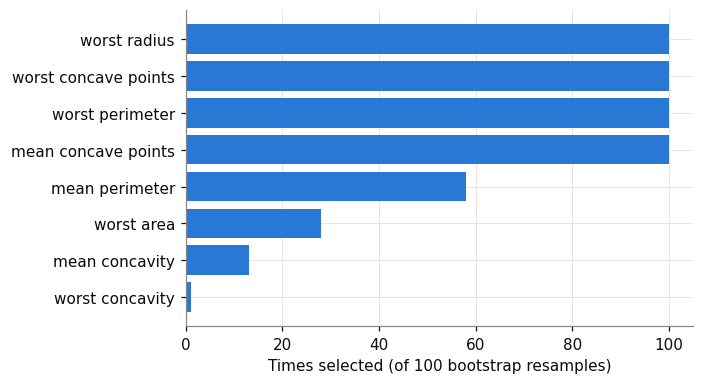

In [5]:
rng = np.random.default_rng(0)
K, B = 5, 100
picked = []
for _ in range(B):
    idx = rng.integers(0, len(ydev), len(ydev))
    sel = SelectKBest(f_classif, k=K).fit(Xdev.iloc[idx], ydev.iloc[idx])
    picked.append(set(np.array(names)[sel.get_support()]))
freq = pd.Series([n for s in picked for n in s]).value_counts()
print("選ばれた回数（100 回中）の上位:\n", freq.head(10).to_string())
print("\nちょうど同じ 5 個の組が選ばれた回数の最大:", pd.Series([tuple(sorted(s)) for s in picked]).value_counts().iloc[0], "/ 100")
jac = [len(picked[i] & picked[j]) / len(picked[i] | picked[j]) for i in range(B) for j in range(i + 1, B)]
print("2 回の選択の重なり（Jaccard）の平均:", round(float(np.mean(jac)), 3))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
top = freq.head(10)[::-1]
ax.barh(top.index, top.values, color=BLUE)
ax.set_xlabel("Times selected (of 100 bootstrap resamples)")
plt.tight_layout(); plt.show()

In [6]:
rng = np.random.default_rng(0)
K, B = 10, 100
picked = []
for _ in range(B):
    idx = rng.integers(0, len(ydev), len(ydev))
    sel = SelectKBest(f_classif, k=K).fit(Xdev.iloc[idx], ydev.iloc[idx])
    picked.append(set(np.array(names)[sel.get_support()]))
freq = pd.Series([n for s in picked for n in s]).value_counts()
print("選ばれた回数（100 回中）の上位:\n", freq.head(10).to_string())
jac = [len(picked[i] & picked[j]) / len(picked[i] | picked[j]) for i in range(B) for j in range(i + 1, B)]
print("2 回の選択の重なり（Jaccard）の平均:", round(float(np.mean(jac)), 3))
print("100 回すべてで選ばれた特徴量の数:", int((freq == 100).sum()))

選ばれた回数（100 回中）の上位:
 mean perimeter          100
worst radius            100
worst concave points    100
worst perimeter         100
mean radius             100
worst area              100
mean concave points     100
mean concavity           99
mean area                97
worst concavity          92
2 回の選択の重なり（Jaccard）の平均: 0.959
100 回すべてで選ばれた特徴量の数: 7


In [7]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000))
apparent = roc_auc_score(ydev, model.fit(Xdev, ydev).predict_proba(Xdev)[:, 1])
rng = np.random.default_rng(0)
opt = []
for _ in range(200):
    idx = rng.integers(0, len(ydev), len(ydev))
    Xb, yb = Xdev.iloc[idx], ydev.iloc[idx]
    if yb.nunique() < 2: continue
    m = model.fit(Xb, yb)
    a_boot = roc_auc_score(yb, m.predict_proba(Xb)[:, 1])
    a_orig = roc_auc_score(ydev, m.predict_proba(Xdev)[:, 1])
    opt.append(a_boot - a_orig)
corrected = apparent - np.mean(opt)
cv_auc = cross_val_score(model, Xdev, ydev, cv=cv5, scoring="roc_auc").mean()
final_auc = roc_auc_score(yte, model.fit(Xdev, ydev).predict_proba(Xte)[:, 1])
print(f"みかけの AUC            : {apparent:.4f}")
print(f"楽観（200 回の平均）    : {np.mean(opt):.4f}")
print(f"補正した AUC            : {corrected:.4f}")
print(f"5 分割交差検証の AUC    : {cv_auc:.4f}")
print(f"テスト用の AUC（1 回）  : {final_auc:.4f}")

みかけの AUC            : 0.9965
楽観（200 回の平均）    : 0.0011
補正した AUC            : 0.9954
5 分割交差検証の AUC    : 0.9944
テスト用の AUC（1 回）  : 0.9917


In [8]:
Xa, Xr, ya, yr = train_test_split(X, y, train_size=40, stratify=y, random_state=0)
apparent40 = roc_auc_score(ya, model.fit(Xa, ya).predict_proba(Xa)[:, 1])
truth40 = roc_auc_score(yr, model.predict_proba(Xr)[:, 1])
rng = np.random.default_rng(0)
opt40 = []
for _ in range(200):
    idx = rng.integers(0, len(ya), len(ya))
    Xb, yb = Xa.iloc[idx], ya.iloc[idx]
    if yb.nunique() < 2: continue
    m = model.fit(Xb, yb)
    opt40.append(roc_auc_score(yb, m.predict_proba(Xb)[:, 1]) - roc_auc_score(ya, m.predict_proba(Xa)[:, 1]))
print("みかけ", round(apparent40, 4), "／ 楽観", round(np.mean(opt40), 4), "／ 補正", round(apparent40 - np.mean(opt40), 4), "／ 本当（529 例）", round(truth40, 4))


みかけ 0.992 ／ 楽観 0.0156 ／ 補正 0.9764 ／ 本当（529 例） 0.966


In [9]:
Xa, Xr, ya, yr = train_test_split(X, y, train_size=40, stratify=y, random_state=0)
rng = np.random.default_rng(0)
opt40 = []
for _ in range(200):
    idx = rng.integers(0, len(ya), len(ya))
    Xb, yb = Xa.iloc[idx], ya.iloc[idx]
    if yb.nunique() < 2: continue
    m = model.fit(Xb, yb)
    opt40.append(roc_auc_score(yb, m.predict_proba(Xb)[:, 1]) - roc_auc_score(yb, m.predict_proba(Xb)[:, 1]))
print("楽観:", round(np.mean(opt40), 4))


楽観: 0.0


In [10]:
Xa, Xr, ya, yr = train_test_split(X, y, train_size=40, stratify=y, random_state=0)
rng = np.random.default_rng(0)
opt40 = []
for _ in range(200):
    idx = rng.integers(0, len(ya), len(ya))
    Xb, yb = Xa.iloc[idx], ya.iloc[idx]
    if yb.nunique() < 2: continue
    m = model.fit(Xb, yb)
    opt40.append(roc_auc_score(yb, m.predict_proba(Xb)[:, 1]) - roc_auc_score(yb, m.predict_proba(Xb)[:, 1]))
print("楽観:", round(np.mean(opt40), 4))

楽観: 0.0


In [11]:
opt40.append(roc_auc_score(yb, m.predict_proba(Xb)[:, 1]) - roc_auc_score(ya, m.predict_proba(Xa)[:, 1]))

In [12]:
Xa, Xr, ya, yr = train_test_split(X, y, train_size=40, stratify=y, random_state=0)
rng = np.random.default_rng(0)
opt40 = []
for _ in range(200):
    idx = rng.integers(0, len(ya), len(ya))
    Xb, yb = Xa.iloc[idx], ya.iloc[idx]
    if yb.nunique() < 2: continue
    m = model.fit(Xb, yb)
    opt40.append(roc_auc_score(yb, m.predict_proba(Xb)[:, 1]) - roc_auc_score(ya, m.predict_proba(Xa)[:, 1]))
print("楽観:", round(np.mean(opt40), 4))

楽観: 0.0156


検証の AUC: {1: np.float64(0.9721), 2: np.float64(0.9912), 3: np.float64(0.9905), 5: np.float64(0.9938), 8: np.float64(0.9942), 10: np.float64(0.9915), 15: np.float64(0.992), 20: np.float64(0.9918), 30: np.float64(0.9915)}
最良: 8 個（AUC 0.9942 ）
1 標準誤差ルールで選ぶ成分数: 5


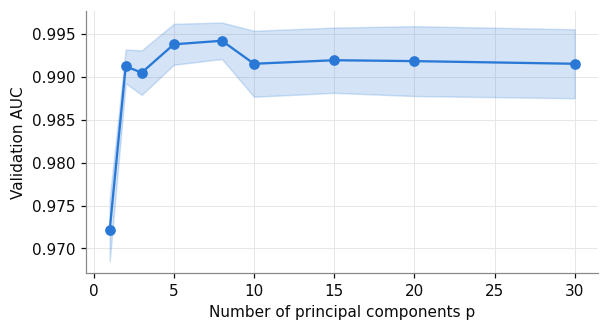

In [13]:
pca_pipe = make_pipeline(StandardScaler(), PCA(), LogisticRegression(max_iter=1000))
ps = [1, 2, 3, 5, 8, 10, 15, 20, 30]
gs = GridSearchCV(pca_pipe, {"pca__n_components": ps}, cv=cv5, scoring="roc_auc").fit(Xdev, ydev)
print("検証の AUC:", dict(zip(ps, gs.cv_results_["mean_test_score"].round(4))))
print("最良:", gs.best_params_["pca__n_components"], "個（AUC", round(gs.best_score_, 4), "）")
mean, sd = gs.cv_results_["mean_test_score"], gs.cv_results_["std_test_score"]
b = int(np.argmax(mean)); thr = mean[b] - sd[b] / np.sqrt(5)
choice = ps[int(np.argmax(mean >= thr))]
print("1 標準誤差ルールで選ぶ成分数:", choice)

fig, ax = plt.subplots(figsize=(6, 3.1))
se = sd / np.sqrt(5)
ax.plot(ps, mean, "o-", color=BLUE); ax.fill_between(ps, mean - se, mean + se, color=BLUE, alpha=0.2)
ax.set_xlabel("Number of principal components p"); ax.set_ylabel("Validation AUC")
plt.show()